# TP: Estimación de movimiento y seguimiento de objetos

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

El objetivo es comprender los pasos del pipeline completo:

`Imagen → Preprocesamiento → Modelado de fondo / detección → Seguimiento → Análisis`

No se muestran *todas* las técnicas, sino un subconjunto representativo, y cada bloque termina en una **aplicación real**:

| Bloque | Técnicas usadas | Aplicación real |
|---|---|---|
| 1. Preprocesamiento | Filtros espaciales, ROI, submuestreo | Robustez frente a ruido de sensor |
| 2. Modelado de fondo | Diferencia de cuadros, promedio móvil, **MOG2**, **KNN**, **CNT** | Comparación de costo/calidad |
| 3. Objeto abandonado | Dos MOG2 con distinta tasa de aprendizaje | Alarma de seguridad (equipaje olvidado) |
| 4. Multi-objeto | MOG2 + **Kalman** + asignación húngara | Conteo bidireccional, mapa de calor, tiempo de permanencia, velocidad |
| 5. Flujo óptico | **Farnebäck**, **DIS**, **Lucas-Kanade + GFTT** | Estabilización de video y detección de contraflujo |
| 6. Seguimiento de un objeto | **KCF, MOSSE, CSRT, TLD** | Prueba de oclusión (corta y larga) y cámara PTZ digital (auto-encuadre) |

**Cómo se usa:** ejecutar las celdas en orden. Al final de cada sección hay **consignas y reflexiones** para el informe del TP.

> Los tiempos (FPS) dependen de tu máquina; lo importante es la comparación *relativa* entre métodos.

## Celda de Configuración Inicial
Ejecutá esta celda para instalar/cargar las dependencias esenciales para este práctico.

In [1]:
# Si hace falta, descomentar. Se usa la versión "headless" (no abre ventanas, ideal para notebooks).
# El paquete "contrib" incluye cv2.bgsegm (CNT, GSOC, ...) y los trackers legacy (MOSSE, TLD, ...)
%pip install -q opencv-contrib-python-headless numpy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\Admin\Desktop\git\vision\.venv\Scripts\python.exe: No module named pip


In [2]:
import cv2, time, shutil, subprocess, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from IPython.display import Video, display


In [3]:

plt.rcParams['figure.dpi'] = 110
print('OpenCV', cv2.__version__)
assert hasattr(cv2, 'bgsegm') and hasattr(cv2, 'legacy'), \
    'Instalar opencv-contrib-python-headless (y desinstalar opencv-python si estaba instalado)'

DATOS = Path('datos');   DATOS.mkdir(exist_ok=True)
SALIDAS = Path('salidas'); SALIDAS.mkdir(exist_ok=True)

# Video de muestra: peatones (escena PETS, cámara fija). Se descarga la primera vez.
# Para usar TU video: poner su ruta en VIDEO_PROPIO (ej. 'datos/mi_video.mp4').
VIDEO_PROPIO = None
URL_PEATONES = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi'

def obtener_video():
    if VIDEO_PROPIO: return VIDEO_PROPIO
    ruta = DATOS / 'vtest.avi'
    if not ruta.exists():
        print('Descargando video de muestra...'); urllib.request.urlretrieve(URL_PEATONES, ruta)
    return str(ruta)

OpenCV 4.14.0


In [4]:
# ---------- utilidades generales  ----------
def leer_frames(ruta, max_frames=400, escala=0.6, inicio=0):
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    cap.set(cv2.CAP_PROP_POS_FRAMES, inicio)
    frames = []
    while len(frames) < max_frames:
        ok, f = cap.read()
        if not ok: break
        if escala != 1: f = cv2.resize(f, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
        frames.append(f)
    cap.release()
    return frames, fps

def gris(f): 
    return cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)

def mostrar(imgs, titulos=None, cols=3, ancho=5, cmap='gray'):
    n = len(imgs); filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * 0.72 * filas))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis('off')
    for i, im in enumerate(imgs):
        if im.ndim == 3: axs[i].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:            axs[i].imshow(im, cmap=cmap, vmin=0, vmax=255)
        if titulos: axs[i].set_title(titulos[i], fontsize=10)
    plt.tight_layout(); plt.show()

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx)); iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter + 1e-9)

def nuevo_writer(nombre, fps, tam):
    ruta = SALIDAS / nombre
    return cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*'mp4v'), fps, tam), ruta

def ver_video(ruta, ancho=560):
    # mp4v no siempre se reproduce en el navegador: si hay ffmpeg se recodifica a H.264
    ruta = Path(ruta)
    if shutil.which('ffmpeg'):
        h264 = ruta.with_name(ruta.stem + '_h264.mp4')
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(ruta), '-vcodec', 'libx264',
                        '-pix_fmt', 'yuv420p', str(h264)])
        if h264.exists():
            display(Video(str(h264), embed=True, width=ancho)); return
    print(f'Video guardado en {ruta} (abrirlo con un reproductor externo).')



400 frames de 461x346 a 10 fps


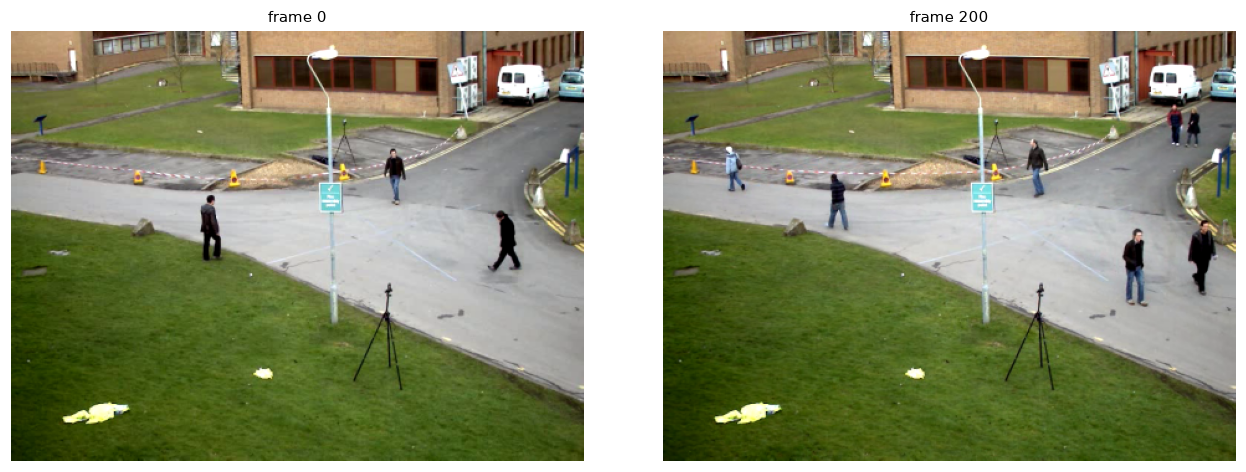

In [5]:
ESCALA = 0.6                       # los cuadros de trabajo se reducen para acelerar el procesamiento
frames, FPS = leer_frames(obtener_video(), max_frames=400, escala=ESCALA)
H, W = frames[0].shape[:2]
print(f'{len(frames)} frames de {W}x{H} a {FPS:.0f} fps')
mostrar([frames[0], frames[200]], ['frame 0', 'frame 200'], cols=2, ancho=6)

## Funciones auxiliares del Ejercicio 2 (post-proceso de la máscara)
Se necesitan en este notebook: `limpiar_mascara`, `detectar_blobs`, `dibujar_cajas`.

In [6]:
# Definición de los elementos estructurantes que usaremos (elipses de kxk)
K_OPEN = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
K_CLOSE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

def limpiar_mascara(m):
    # Con MOG2/KNN y detectShadows=True:
    #   0   = fondo, 127 = sombra, 255 = primer plano
    # El umbral > 200 conserva solamente el primer plano.
    _, b = cv2.threshold(m, 200, 255, cv2.THRESH_BINARY)

    # Apertura: elimina pequeños elementos aislados y ruido puntual.
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, K_OPEN)
    # Cierre: rellena pequeños huecos y une fragmentos cercanos.
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, K_CLOSE)
    return b

def detectar_blobs(mask, area_min=120):
    # Buscar únicamente contornos externos de las regiones detectadas.
    cnts, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    # Conservar solamente las regiones cuya área supere el mínimo establecido.
    return [
        cv2.boundingRect(c)
        for c in cnts
        if cv2.contourArea(c) >= area_min
    ]

def dibujar_cajas(f, cajas, color=(0, 255, 0)):
    # Dibujar las cajas delimitadoras sobre una copia del frame original.
    g = f.copy()
    for x, y, w, h in cajas:
        cv2.rectangle(g, (x, y), (x + w, y + h), color, 2)
    return g


## 6. Seguimiento de un objeto elegido por el usuario

Hasta acá el sistema detectó y siguió **todo lo que se mueve**. Ahora cambiamos el problema: el usuario **elige un único objeto con un clic** y un tracker de un solo objeto lo sigue durante un tramo del video.

Se pueden comparar distintos algoritmos clásicos de seguimiento:

| Tracker | Idea |
|---|---|
| **MOSSE** | Filtro de correlación en frecuencia (FFT). Muy rápido, pero menos robusto ante cambios de escala, deformaciones u oclusiones. |
| **KCF** | Filtro de correlación kernelizado. Rápido y preciso en situaciones relativamente estables; utiliza una caja de tamaño fijo. |
| **CSRT** | Utiliza confiabilidad espacial y de canal. Es más lento, pero generalmente más robusto y permite adaptar mejor la caja a cambios de escala y apariencia. |
| **TLD** | Combina seguimiento, detección y aprendizaje. Puede recuperar el objeto después de perderlo, pero puede resultar inestable y confundirlo con otros objetos. |

Sobre la pista obtenida construiremos tres aplicaciones:

- **Reflector:** resalta el objeto seleccionado, dibuja su trayectoria mediante una estela y estima su velocidad.
- **Anonimización:** aplica un desenfoque o máscara únicamente sobre el objeto seleccionado, manteniendo el resto de la escena sin modificar.
- **Cámara PTZ digital:** utiliza la posición del objeto seguido para desplazar y recortar digitalmente la imagen, manteniendo al objeto aproximadamente centrado.

> 💡 **Idea clave:** a diferencia del seguimiento multi-objeto de la sección anterior, aquí no necesitamos descubrir qué objetos existen en la escena. El usuario proporciona inicialmente **qué objeto quiere seguir** (en el video de ejemplo son personas)  y el tracker intenta mantener su identidad a lo largo de los cuadros siguientes.

In [7]:
# ==== 6.1 Preparación: funciones, tramo de video a resolución completa y personas detectadas ====
# En esta sección el usuario elegirá una persona mediante una caja inicial.
# Los trackers trabajan directamente sobre el video a resolución completa,
# ya que necesitan suficiente textura y detalle para seguir el objeto.

def crear_tracker(nombre):
    # Crea el tracker solicitado. MOSSE y TLD se encuentran en cv2.legacy
    # en algunas versiones de OpenCV, mientras que KCF, CSRT y MIL pueden
    # estar disponibles directamente en cv2.
    f = {
        'MOSSE': lambda: cv2.legacy.TrackerMOSSE_create(),
        'KCF':   lambda: cv2.TrackerKCF_create(),
        'CSRT':  lambda: cv2.TrackerCSRT_create(),
        'TLD':   lambda: cv2.legacy.TrackerTLD_create(),
        'MIL':   lambda: cv2.TrackerMIL_create(),
    }
    return f[nombre]()

def correr_tracker(trk, frames_, bbox0, n):
    # Inicializa el tracker con la caja seleccionada y lo actualiza cuadro a cuadro.
    # Se guarda una caja por cuadro (None si el tracker pierde el objeto) y se
    # mide el tiempo medio de cada actualización.
    trk.init(frames_[0], tuple(int(v) for v in bbox0)); cajas = [tuple(bbox0)]; t = 0
    for f in frames_[1:n]:
        t0 = time.perf_counter(); ok, bb = trk.update(f); t += time.perf_counter() - t0
        cajas.append(tuple(bb) if ok else None)
    return cajas, 1000 * t / max(n - 1, 1)

def agrandar(c, factor):                      # escala la caja alrededor de su centro para dar contexto al tracker
    x, y, w, h = c; cx, cy = x + w / 2, y + h / 2
    return (int(round(cx - w * factor / 2)), int(round(cy - h * factor / 2)), int(round(w * factor)), int(round(h * factor)))

def limitar_caja(c, W_, H_):                  # mantiene la caja dentro de los límites del cuadro
    x, y, w, h = c; x0, y0 = max(x, 0), max(y, 0); x1, y1 = min(x + w, W_ - 1), min(y + h, H_ - 1)
    return (x0, y0, max(x1 - x0, 2), max(y1 - y0, 2))

def centro(c): return None if c is None else (c[0] + c[2] / 2, c[1] + c[3] / 2)

# ---------------- parámetros de esta sección ----------------
FRAME_OBJ = 179       # cuadro del video (índice sobre `frames`) en el que se elige a la persona
NFR       = 100       # cantidad de cuadros que se siguen a partir del cuadro seleccionado
CONTEXTO  = 2.0       # la caja inicial se agranda ×2 para dar contexto a los filtros de correlación

# Tramo de video a RESOLUCIÓN COMPLETA. Los trackers necesitan textura y detalle:
# a escala 0.6 una persona mide aproximadamente 15×45 px, lo que dificulta el seguimiento.
frames_hr, _ = leer_frames(obtener_video(), max_frames=NFR, escala=1.0, inicio=FRAME_OBJ)
H6, W6 = frames_hr[0].shape[:2]

# Personas detectadas en el cuadro FRAME_OBJ mediante MOG2 + morfología
# (secciones 2 y 4). La detección se realiza sobre `frames`, que está a la
# escala de trabajo, y las cajas se convierten después a coordenadas de
# resolución completa dividiendo por ESCALA.
def detectar_personas(frames_trabajo, idx, calentamiento=100):
    # Creamos un modelo MOG2 y lo calentamos con cuadros anteriores al cuadro
    # elegido para que el fondo esté adaptado antes de obtener la máscara.
    mog = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=30, detectShadows=True)
    for f in frames_trabajo[max(0, idx - calentamiento): idx + 1]:
        m = mog.apply(cv2.GaussianBlur(f, (5, 5), 0))

    # Limpiamos la máscara, extraemos blobs y descartamos regiones pequeñas.
    cajas = detectar_blobs(limpiar_mascara(m), area_min=90)

    # Las detecciones están en coordenadas de `frames`; las llevamos a la
    # resolución completa utilizada por los trackers.
    return [tuple(int(v / ESCALA) for v in c) for c in cajas]

cajas_det = detectar_personas(frames, FRAME_OBJ)
print(f'{len(cajas_det)} objetos detectados en el cuadro {FRAME_OBJ}')

6 objetos detectados en el cuadro 179


In [8]:
# Requiere el backend interactivo de Jupyter:
%pip install -q ipympl   # (y reiniciar el kernel la primera vez)
# En Google Colab, antes: from google.colab import output; output.enable_custom_widget_manager()

Note: you may need to restart the kernel to use updated packages.


c:\Users\Admin\Desktop\git\vision\.venv\Scripts\python.exe: No module named pip


In [ ]:
# ==== 6.2 Selección INTERACTIVA (alternativa con botones): elegí el número de la persona a seguir ====
# Mostramos las detecciones del cuadro seleccionado y permitimos elegir una
# mediante botones. La caja elegida queda almacenada en `seleccion` para que
# las siguientes etapas puedan utilizarla sin volver a seleccionar el objeto.
import ipywidgets as widgets
from IPython.display import display, clear_output, Image as ImagenIPy

PUNTO_OBJ = (508, 263)     # RESPALDO (se usa en 6.3 si no elegís nada)
seleccion = {'caja': None}

def imagen_con_detecciones(elegida=None):
    # Dibuja todas las detecciones numeradas y resalta en rojo la seleccionada.
    g = frames_hr[0].copy()
    for i, (x, y, w, h) in enumerate(cajas_det):
        col = (0, 0, 255) if i == elegida else (0, 255, 0)
        cv2.rectangle(g, (x, y), (x + w, y + h), col, 3 if i == elegida else 2)
        cv2.putText(g, str(i + 1), (x, max(y - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, .8, col, 2, cv2.LINE_AA)
    return ImagenIPy(data=cv2.imencode('.png', g)[1].tobytes())

salida = widgets.Output()

# Cada botón representa una de las personas/objetos detectados.
# `index=None` evita seleccionar una opción automáticamente.
botones = widgets.ToggleButtons(options=[(f'#{i + 1}', i) for i in range(len(cajas_det))], index=None,
                                description='Persona:', tooltips=[f'Objeto {i + 1}' for i in range(len(cajas_det))])

def al_elegir(cambio):
    # Cuando el usuario selecciona un botón, guardamos la caja correspondiente
    # y mostramos nuevamente la imagen destacando el objeto elegido.
    i = cambio['new']
    if i is None: return
    seleccion['caja'] = cajas_det[i]
    with salida:
        clear_output(wait=True); print(f'Seleccionado objeto #{i + 1}: caja {cajas_det[i]}. Ahora ejecutá la celda 6.3.')
        display(imagen_con_detecciones(i))

botones.observe(al_elegir, names='value')
display(botones, salida)

# Mostramos inicialmente todas las detecciones sin ninguna seleccionada.
with salida: display(imagen_con_detecciones())

ToggleButtons(description='Persona:', options=(('#1', 0), ('#2', 1), ('#3', 2), ('#4', 3), ('#5', 4), ('#6', 5…

Output()

In [ ]:
# ==== 6.3 Seguimiento con el tracker elegido (ejecutar DESPUÉS de hacer clic) ====
%matplotlib inline

TRACKER = 'CSRT'        # 'MOSSE' | 'KCF' | 'CSRT' | 'TLD'

# Si no se seleccionó ninguna persona, usamos un punto de respaldo para
# encontrar automáticamente la primera detección que lo contiene.
if seleccion['caja'] is None:
    print('No hubo clic: se usa PUNTO_OBJ =', PUNTO_OBJ)
    cand = [c for c in cajas_det if c[0] <= PUNTO_OBJ[0] <= c[0] + c[2] and c[1] <= PUNTO_OBJ[1] <= c[1] + c[3]]
    assert cand, 'PUNTO_OBJ no cae sobre ninguna detección: ajustarlo o hacer clic en la celda anterior'
    seleccion['caja'] = cand[0]

# BBOX_AJUSTADA es la detección original, que intenta ajustarse al objeto.
# Para inicializar el tracker la ampliamos con CONTEXTO: los trackers de
# correlación pueden beneficiarse de información adicional alrededor del objeto.
BBOX_AJUSTADA = seleccion['caja']
BBOX0 = limitar_caja(agrandar(BBOX_AJUSTADA, CONTEXTO), W6, H6)

# Ejecutamos el tracker sobre el tramo de video a resolución completa.
# ms_seg es el tiempo medio de cada llamada a update(), sin incluir captura,
# dibujo ni escritura del video.
cajas_seg, ms_seg = correr_tracker(crear_tracker(TRACKER), frames_hr, BBOX0, NFR)
print(f'{TRACKER}: {1000 / ms_seg:.0f} FPS (solo update) | cuadros con pérdida reportada: {sum(c is None for c in cajas_seg)} de {NFR}')


def video_seguimiento(frames_, cajas, nombre_tracker, nombre='seguimiento.mp4'):
    # Generamos un video mostrando la caja seguida y la trayectoria acumulada.
    # Si el tracker pierde el objeto, conservamos la última caja conocida y
    # la mostramos en naranja para diferenciarla de una detección válida.
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6)); ultima, tray, salida = cajas[0], [], []

    for f, c in zip(frames_, cajas):
        g = f.copy(); perdido = c is None
        if not perdido: ultima = c

        # El tracker fue inicializado con una caja ampliada. Para visualizar
        # nuevamente la caja correspondiente al objeto original, la reducimos
        # por el mismo factor CONTEXTO.
        x, y, w, h = [int(v) for v in agrandar(ultima, 1 / CONTEXTO)]

        col = (0, 165, 255) if perdido else (0, 255, 0)
        cv2.rectangle(g, (x, y), (x + w, y + h), col, 2)

        # Guardamos el centro de la caja para construir la estela.
        tray.append(centro(ultima))
        if len(tray) > 1:
            cv2.polylines(g, [np.array(tray, np.int32).reshape(-1, 1, 2)], False, (0, 255, 255), 2, cv2.LINE_AA)

        # Indicamos qué tracker se está utilizando y, si corresponde,
        # que en ese cuadro no se obtuvo una actualización válida.
        cv2.putText(g, f'{nombre_tracker}' + ('  (PERDIDO)' if perdido else ''), (10, 26), cv2.FONT_HERSHEY_SIMPLEX, .8, col, 2, cv2.LINE_AA)

        vw.write(g); salida.append(g)

    vw.release()
    return ruta, salida


ruta_seg, frames_seg = video_seguimiento(frames_hr, cajas_seg, TRACKER)

# mostrar([frames_seg[0], frames_seg[NFR // 2], frames_seg[-1]], ['Inicio', 'Mitad', 'Final'], cols=3, ancho=6)
ver_video(ruta_seg, ancho=768)

In [ ]:
# ==== 6.4 Aplicación: REFLECTOR + estela + velocidad (efecto cinematográfico / análisis de movimiento) ====
# El tracker ya proporciona una caja por cuadro. A partir de ella podemos
# construir aplicaciones visuales y métricas de movimiento sin volver a detectar
# el objeto: resaltamos la persona, mostramos su trayectoria y estimamos su velocidad.
M_POR_PX = None          # si conocés la escala real (m por píxel del video a resolución completa), ponela aquí

def video_reflector(frames_, cajas, nombre='reflector.mp4', vent_vel=5):
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6))
    tray, dist_total, ultimo = [], 0.0, cajas[0]

    for f, cj in zip(frames_, cajas):
        # Si el tracker perdió temporalmente el objeto, conservamos la última
        # posición conocida para mantener el reflector y la trayectoria.
        if cj is not None: ultimo = cj
        p = agrandar(ultimo, 1 / CONTEXTO); c = centro(p)

        # Acumulamos la distancia recorrida por el centro de la caja.
        # En ausencia de calibración queda expresada en píxeles.
        if tray: dist_total += np.hypot(c[0] - tray[-1][0], c[1] - tray[-1][1])
        tray.append(c)

        # Fondo apagado (oscuro y desaturado) + elipse "iluminada" alrededor
        # de la persona. El desenfoque de la máscara genera un borde suave.
        fondo_ap = (cv2.cvtColor(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR) * 0.35).astype(np.uint8)
        m = np.zeros(f.shape[:2], np.uint8); cv2.ellipse(m, (int(c[0]), int(c[1])), (int(p[2] * 1.1), int(p[3] * 0.75)), 0, 0, 360, 255, -1)
        m = cv2.GaussianBlur(m, (0, 0), 14).astype(np.float32)[..., None] / 255.0
        out = (f * m + fondo_ap * (1 - m)).astype(np.uint8)

        # Estela de los últimos 60 centros. Cuanto más reciente es el punto,
        # más gruesa/intensa resulta la línea, facilitando la percepción del movimiento.
        pts = tray[-60:]
        for i in range(1, len(pts)):
            a = i / len(pts); cv2.line(out, (int(pts[i - 1][0]), int(pts[i - 1][1])), (int(pts[i][0]), int(pts[i][1])),
                                       (0, int(255 * a), int(255 * (1 - a) + 80)), max(1, int(4 * a)), cv2.LINE_AA)

        # Velocidad media durante los últimos `vent_vel` cuadros.
        # Sin calibración se expresa en px/s. Si M_POR_PX está definido,
        # se convierte a m/s.
        k0 = max(0, len(tray) - 1 - vent_vel)
        v = np.hypot(tray[-1][0] - tray[k0][0], tray[-1][1] - tray[k0][1]) / max(len(tray) - 1 - k0, 1) * FPS
        u, esc = ('m/s', M_POR_PX) if M_POR_PX else ('px/s', 1)

        cv2.putText(out, f'velocidad: {v * esc:5.1f} {u}', (12, 28), cv2.FONT_HERSHEY_SIMPLEX, .7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(out, f'recorrido: {dist_total * esc:6.1f} {u.split("/")[0]}', (12, 56), cv2.FONT_HERSHEY_SIMPLEX, .7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.rectangle(out, (int(p[0]), int(p[1])), (int(p[0] + p[2]), int(p[1] + p[3])), (0, 255, 255), 1)
        vw.write(out)

    vw.release(); return ruta, out

ruta_ref, ultimo_ref = video_reflector(frames_hr, cajas_seg)
# mostrar([ultimo_ref], ['Último cuadro: reflector + estela + velocidad'], cols=1, ancho=7)
ver_video(ruta_ref, ancho=768)

In [ ]:
# ==== 6.5 Aplicación: ANONIMIZACIÓN de una persona (privacidad en videovigilancia) ====
# Utilizamos la posición estimada por el tracker para anonimizar únicamente
# el objeto seleccionado, sin modificar el resto de la escena.

def pixelar(img, caja, bloques=12):
    # Divide la región en bloques pequeños y la vuelve a ampliar con INTER_NEAREST.
    # El resultado conserva los bloques de color y produce el efecto de pixelado.
    x, y, w, h = [int(v) for v in caja]
    x0, y0, x1, y1 = max(x, 0), max(y, 0), min(x + w, img.shape[1]), min(y + h, img.shape[0])
    if x1 - x0 < 2 or y1 - y0 < 2: return
    peq = cv2.resize(img[y0:y1, x0:x1], (max(1, (x1 - x0) // bloques), max(1, (y1 - y0) // bloques)), interpolation=cv2.INTER_AREA)
    img[y0:y1, x0:x1] = cv2.resize(peq, (x1 - x0, y1 - y0), interpolation=cv2.INTER_NEAREST)

def video_anonimizado(frames_, cajas, margen=1.4, nombre='anonimizacion.mp4'):
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6)); ultima = cajas[0]; salida = []

    for f, c in zip(frames_, cajas):
        # Si el tracker pierde temporalmente el objeto, conservamos la última
        # posición conocida para evitar que la persona quede expuesta.
        if c is not None: ultima = c

        g = f.copy()

        # El tracker fue inicializado con una caja ampliada mediante CONTEXTO.
        # `margen / CONTEXTO` vuelve a aproximar la caja al objeto y agrega
        # un margen adicional para cubrir mejor sus bordes.
        pixelar(g, agrandar(ultima, margen / CONTEXTO))

        vw.write(g); salida.append(g)

    vw.release(); return ruta, salida

ruta_anon, frames_anon = video_anonimizado(frames_hr, cajas_seg)
k = NFR // 2
# mostrar([frames_hr[k], frames_anon[k]], ['Original', f'Anonimizado (persona seguida con {TRACKER})'], cols=2, ancho=8)
ver_video(ruta_anon, ancho=768)

In [ ]:
# ==== 6.6 Cámara PTZ digital (auto-encuadre) ====
# Simulamos una cámara PTZ utilizando una cámara fija: una ventana de recorte
# sigue al objeto y luego se redimensiona a la resolución de salida.
# No hay movimiento físico de la cámara; solo cambia la región observada.

def ptz_digital(frames_, cajas, ancho_rec=int(W6 * .38), alfa=0.12, salida=(360, 270)):
    h_, w_ = frames_[0].shape[:2]
    alto_rec = int(ancho_rec * salida[1] / salida[0])
    vw, ruta = nuevo_writer('ptz_digital.mp4', FPS, salida); c = None; muestras = []; ultima = cajas[0]

    for f, cj in zip(frames_, cajas):
        # Si el tracker pierde temporalmente el objeto, mantenemos la última
        # posición conocida para evitar que el encuadre salte.
        if cj is not None: ultima = cj

        # Centro actual del objeto y suavizado exponencial:
        # alfa pequeño = cámara virtual más suave pero con mayor retraso;
        # alfa grande = respuesta más rápida pero potencialmente más brusca.
        obj = np.array(centro(ultima))
        c = obj if c is None else (1 - alfa) * c + alfa * obj

        # Calculamos la esquina superior izquierda de la ventana y la limitamos
        # para que el recorte nunca salga de los límites del cuadro original.
        x0 = int(np.clip(c[0] - ancho_rec / 2, 0, w_ - ancho_rec))
        y0 = int(np.clip(c[1] - alto_rec / 2, 0, h_ - alto_rec))

        # Recortamos la región seguida y la redimensionamos a la salida.
        # El cambio de posición del recorte simula el movimiento de una cámara PTZ.
        rec = cv2.resize(f[y0:y0 + alto_rec, x0:x0 + ancho_rec], salida, interpolation=cv2.INTER_LINEAR)

        vw.write(rec); muestras.append((f, rec, (x0, y0, ancho_rec, alto_rec)))

    vw.release(); return ruta, muestras

ruta_ptz, muestras = ptz_digital(frames_hr, cajas_seg)

# Visualizamos algunos cuadros mostrando sobre la imagen original la ventana
# que corresponde a la salida de la cámara PTZ digital.
imgs = []
for f, rec, (x0, y0, aw, ah) in [muestras[i] for i in (5, len(muestras) // 2, len(muestras) - 5)]:
    g_ = f.copy(); cv2.rectangle(g_, (x0, y0), (x0 + aw, y0 + ah), (0, 255, 255), 3); imgs += [g_, rec]

# mostrar(imgs, ['Cámara fija + ventana', 'Salida PTZ'] * 3, cols=4, ancho=4.2)
ver_video(ruta_ptz, ancho=360)